# D2 – Machine Learning Model Report (CLO3)
**Course:** CDS 2413 – Introduction to Data Science  
**Dataset:** Student Performance Factors (`StudentPerformanceFactors.csv`)  
**Dependent variable:** `Exam_Score`

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
warnings.filterwarnings('ignore')
os.makedirs('figs', exist_ok=True)
pd.set_option('display.width', 220)
pd.set_option('display.max_columns', 40)
sns.set_style('whitegrid')

# PART 1 – PREPROCESSING
## 1.1 Data Collection

In [2]:
df = pd.read_csv('StudentPerformanceFactors.csv')      # pandas reads the CSV file
print('Shape (rows, columns):', df.shape)
display(df.head())
df.info()

Shape (rows, columns): (6607, 20)


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


<class 'pandas.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   Hours_Studied               6607 non-null   int64
 1   Attendance                  6607 non-null   int64
 2   Parental_Involvement        6607 non-null   str  
 3   Access_to_Resources         6607 non-null   str  
 4   Extracurricular_Activities  6607 non-null   str  
 5   Sleep_Hours                 6607 non-null   int64
 6   Previous_Scores             6607 non-null   int64
 7   Motivation_Level            6607 non-null   str  
 8   Internet_Access             6607 non-null   str  
 9   Tutoring_Sessions           6607 non-null   int64
 10  Family_Income               6607 non-null   str  
 11  Teacher_Quality             6529 non-null   str  
 12  School_Type                 6607 non-null   str  
 13  Peer_Influence              6607 non-null   str  
 14  Physical_Activity  

In [3]:
# Separate dependent (target) and independent variables
target = 'Exam_Score'
X_raw = df.drop(columns=[target])      # independent variables
y_raw = df[target]                     # dependent variable
print('Dependent variable  :', target)
print('Independent variables (%d):' % X_raw.shape[1])
print(list(X_raw.columns))

Dependent variable  : Exam_Score
Independent variables (19):
['Hours_Studied', 'Attendance', 'Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours', 'Previous_Scores', 'Motivation_Level', 'Internet_Access', 'Tutoring_Sessions', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Physical_Activity', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender']


## 1.2 Data Cleaning

In [4]:
print('Missing values per column:')
print(df.isnull().sum()[df.isnull().sum() > 0])
print('\nDuplicate rows:', df.duplicated().sum())

Missing values per column:
Teacher_Quality             78
Parental_Education_Level    90
Distance_from_Home          67
dtype: int64

Duplicate rows: 0


In [5]:
cat_cols = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]
num_all  = [c for c in df.columns if pd.api.types.is_numeric_dtype(df[c])]

# Categorical columns -> fill missing values with the MODE (most frequent value)
for c in cat_cols:
    if df[c].isnull().any():
        mode_val = df[c].mode()[0]
        print(f'{c}: filled {df[c].isnull().sum()} missing values with mode = {mode_val}')
        df[c] = df[c].fillna(mode_val)
# Numerical columns -> fill missing values with the MEAN (none are missing, kept for completeness)
for c in num_all:
    if df[c].isnull().any():
        df[c] = df[c].fillna(df[c].mean())

df = df.drop_duplicates()
print('\nMissing values after cleaning:', df.isnull().sum().sum())
print('Rows after cleaning:', df.shape[0])

Teacher_Quality: filled 78 missing values with mode = Medium
Parental_Education_Level: filled 90 missing values with mode = High School
Distance_from_Home: filled 67 missing values with mode = Near

Missing values after cleaning: 0
Rows after cleaning: 6607


## 1.3 Treating the Categorical Variables

In [6]:
ordinal_maps = {
    'Parental_Involvement'    : {'Low':0, 'Medium':1, 'High':2},
    'Access_to_Resources'     : {'Low':0, 'Medium':1, 'High':2},
    'Motivation_Level'        : {'Low':0, 'Medium':1, 'High':2},
    'Family_Income'           : {'Low':0, 'Medium':1, 'High':2},
    'Teacher_Quality'         : {'Low':0, 'Medium':1, 'High':2},
    'Peer_Influence'          : {'Negative':0, 'Neutral':1, 'Positive':2},
    'Parental_Education_Level': {'High School':0, 'College':1, 'Postgraduate':2},
    'Distance_from_Home'      : {'Near':0, 'Moderate':1, 'Far':2},
}
binary_maps = {
    'Extracurricular_Activities': {'No':0, 'Yes':1},
    'Internet_Access'           : {'No':0, 'Yes':1},
    'Learning_Disabilities'     : {'No':0, 'Yes':1},
    'School_Type'               : {'Public':0, 'Private':1},
    'Gender'                    : {'Female':0, 'Male':1},
}
summary = pd.DataFrame({
    'Variable' : list(ordinal_maps) + list(binary_maps),
    'Type'     : ['Ordinal']*len(ordinal_maps) + ['Binary']*len(binary_maps),
    'Encoding' : ['Ordinal (label) encoding']*len(ordinal_maps) + ['Binary 0/1 encoding']*len(binary_maps),
    'Mapping'  : [str(m) for m in ordinal_maps.values()] + [str(m) for m in binary_maps.values()],
})
display(summary)
print('Nominal variables with more than 2 categories: none -> one-hot encoding is not needed')

df_enc = df.copy()
for col, m in {**ordinal_maps, **binary_maps}.items():
    df_enc[col] = df_enc[col].map(m)
print('\nAll columns numeric now:', all(pd.api.types.is_numeric_dtype(df_enc[c]) for c in df_enc.columns))
display(df_enc.head())

,Variable,Type,Encoding,Mapping
0,Parental_Involvement,Ordinal,Ordinal (label) encoding,"{'Low': 0, 'Medium': 1, 'High': 2}"
1,Access_to_Resources,Ordinal,Ordinal (label) encoding,"{'Low': 0, 'Medium': 1, 'High': 2}"
2,Motivation_Level,Ordinal,Ordinal (label) encoding,"{'Low': 0, 'Medium': 1, 'High': 2}"
3,Family_Income,Ordinal,Ordinal (label) encoding,"{'Low': 0, 'Medium': 1, 'High': 2}"
4,Teacher_Quality,Ordinal,Ordinal (label) encoding,"{'Low': 0, 'Medium': 1, 'High': 2}"
5,Peer_Influence,Ordinal,Ordinal (label) encoding,"{'Negative': 0, 'Neutral': 1, 'Positive': 2}"
6,Parental_Education_Level,Ordinal,Ordinal (label) encoding,"{'High School': 0, 'College': 1, 'Postgraduate..."
7,Distance_from_Home,Ordinal,Ordinal (label) encoding,"{'Near': 0, 'Moderate': 1, 'Far': 2}"
8,Extracurricular_Activities,Binary,Binary 0/1 encoding,"{'No': 0, 'Yes': 1}"
9,Internet_Access,Binary,Binary 0/1 encoding,"{'No': 0, 'Yes': 1}"


Nominal variables with more than 2 categories: none -> one-hot encoding is not needed

All columns numeric now: True


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,0,2,0,7,73,0,1,0,0,1,0,2,3,0,0,0,1,67
1,19,64,0,1,0,8,59,0,1,2,1,1,0,0,4,0,1,1,0,61
2,24,98,1,1,1,7,91,1,1,2,1,1,0,1,4,0,2,0,1,74
3,29,89,0,1,1,8,98,1,1,1,1,1,0,0,4,0,0,1,1,71
4,19,92,1,1,1,6,65,1,1,3,1,2,0,1,4,0,1,0,0,70


## 1.4 Detecting and Removing Outliers (IQR method)

In [7]:
num_cols = ['Hours_Studied','Attendance','Sleep_Hours','Previous_Scores','Tutoring_Sessions','Physical_Activity']
outlier_frames = []
for c in num_cols:
    q1, q3 = df_enc[c].quantile(0.25), df_enc[c].quantile(0.75)
    iqr = q3 - q1
    lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
    out = df_enc[(df_enc[c] < lo) | (df_enc[c] > hi)]
    print(f'{c:20s} bounds = [{lo:6.2f}, {hi:6.2f}]  outliers = {len(out)}')
    outlier_frames.append(out)

# an exam score above 100 is impossible for a percentage score -> invalid record
invalid_target = df_enc[df_enc[target] > 100]
print('Invalid Exam_Score (> 100):', len(invalid_target))
outlier_frames.append(invalid_target)

all_outliers = pd.concat(outlier_frames)
all_outliers = all_outliers[~all_outliers.index.duplicated(keep='first')]   # remove duplicates
print('\nTotal unique outlier rows:', len(all_outliers))

df_clean = df_enc.drop(index=all_outliers.index).reset_index(drop=True)
print('Rows before:', len(df_enc), '| Rows after removing outliers:', len(df_clean))

Hours_Studied        bounds = [  4.00,  36.00]  outliers = 43
Attendance           bounds = [ 40.00, 120.00]  outliers = 0
Sleep_Hours          bounds = [  3.00,  11.00]  outliers = 0
Previous_Scores      bounds = [ 25.50, 125.50]  outliers = 0
Tutoring_Sessions    bounds = [ -0.50,   3.50]  outliers = 430
Physical_Activity    bounds = [ -1.00,   7.00]  outliers = 0
Invalid Exam_Score (> 100): 1

Total unique outlier rows: 473
Rows before: 6607 | Rows after removing outliers: 6134


## 1.5 Splitting the Dataset

In [8]:
from sklearn.model_selection import train_test_split
X = df_clean.drop(columns=[target])
y = df_clean[target]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
print('Training set:', X_train.shape, '(80%)')
print('Testing set :', X_test.shape,  '(20%)')

Training set: (4907, 19) (80%)
Testing set : (1227, 19) (20%)


## 1.6 Featuring the Dataset (Feature Scaling)

In [9]:
from sklearn.preprocessing import StandardScaler
scaler_demo = StandardScaler().fit(X_train[num_cols])      # fitted on TRAINING data only
scaled = pd.DataFrame(scaler_demo.transform(X_train[num_cols]), columns=num_cols)
print('Before scaling (mean / std):')
display(X_train[num_cols].agg(['mean','std']).round(2))
print('After StandardScaler (mean / std):')
display(scaled.agg(['mean','std']).round(2))
# In the models below StandardScaler is placed inside a Pipeline, so it is always fitted on training data only.

Before scaling (mean / std):


,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity
mean,20.00,79.87,7.01,75.12,1.29,2.96
std,5.82,11.51,1.47,14.37,0.98,1.04


After StandardScaler (mean / std):


,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity
mean,0.0,-0.0,0.0,-0.0,-0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0


## Step 4 – Applying Regression Models

In [10]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, ElasticNetCV
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

reg_models = {
    'Multiple Linear Regression'   : make_pipeline(StandardScaler(), LinearRegression()),
    'Polynomial Regression (deg 2)': make_pipeline(PolynomialFeatures(2, include_bias=False), StandardScaler(), LinearRegression()),
    'Ridge Regression'             : make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 13))),
    'Lasso Regression'             : make_pipeline(StandardScaler(), LassoCV(cv=5, random_state=42)),
    'Elastic Net Regression'       : make_pipeline(StandardScaler(), ElasticNetCV(l1_ratio=[0.1, 0.5, 0.9], cv=5, random_state=42)),
}
for name, m in reg_models.items():
    m.fit(X_train, y_train)
print('All 5 regression models trained.')
print('Ridge alpha      :', reg_models['Ridge Regression'][-1].alpha_)
print('Lasso alpha      :', round(reg_models['Lasso Regression'][-1].alpha_, 5))
en = reg_models['Elastic Net Regression'][-1]
print('Elastic Net      : alpha =', round(en.alpha_, 5), ', l1_ratio =', en.l1_ratio_)

All 5 regression models trained.
Ridge alpha      : 10.0
Lasso alpha      : 0.00558
Elastic Net      : alpha = 0.00578 , l1_ratio = 0.9


## Step 5 – Evaluating Models

In [11]:
rows = []
preds = {}
for name, m in reg_models.items():
    p = m.predict(X_test); preds[name] = p
    mse = mean_squared_error(y_test, p)
    rows.append({'Model': name, 'MSE': mse, 'RMSE': np.sqrt(mse),
                 'MAE': mean_absolute_error(y_test, p),
                 'R² (train)': r2_score(y_train, m.predict(X_train)),
                 'R² (test)' : r2_score(y_test, p)})
results = pd.DataFrame(rows)
display(results.round(4))

,Model,MSE,RMSE,MAE,R² (train),R² (test)
0,Multiple Linear Regression,3.2543,1.8040,0.4472,0.7164,0.7611
1,Polynomial Regression (deg 2),3.3704,1.8359,0.5717,0.7268,0.7526
2,Ridge Regression,3.2536,1.8038,0.4473,0.7163,0.7612
3,Lasso Regression,3.2513,1.8031,0.4481,0.7163,0.7614
4,Elastic Net Regression,3.2513,1.8031,0.4481,0.7163,0.7614


## Step 6 – Selecting the Best Model

In [12]:
results_sorted = results.sort_values('R² (test)', ascending=False).reset_index(drop=True)
display(results_sorted.round(4))
best_name = results_sorted.loc[0, 'Model']
best_model = reg_models[best_name]
print('BEST-FIT MODEL (highest R²):', best_name, '| R² =', round(results_sorted.loc[0, 'R² (test)'], 4))

,Model,MSE,RMSE,MAE,R² (train),R² (test)
0,Lasso Regression,3.2513,1.8031,0.4481,0.7163,0.7614
1,Elastic Net Regression,3.2513,1.8031,0.4481,0.7163,0.7614
2,Ridge Regression,3.2536,1.8038,0.4473,0.7163,0.7612
3,Multiple Linear Regression,3.2543,1.8040,0.4472,0.7164,0.7611
4,Polynomial Regression (deg 2),3.3704,1.8359,0.5717,0.7268,0.7526


BEST-FIT MODEL (highest R²): Lasso Regression | R² = 0.7614


## Step 7 – Printing the Regression Equation

In [13]:
def raw_equation(pipe, feature_names):
    '''Convert pipeline (scaler + linear estimator) to an equation in ORIGINAL (unscaled) units.'''
    scaler = pipe.named_steps['standardscaler']
    est = pipe[-1]
    coef = est.coef_ / scaler.scale_
    intercept = est.intercept_ - np.sum(est.coef_ * scaler.mean_ / scaler.scale_)
    return intercept, pd.Series(coef, index=feature_names)

if 'polynomial' in best_name.lower():
    feat_names = best_model.named_steps['polynomialfeatures'].get_feature_names_out(X_train.columns)
else:
    feat_names = list(X_train.columns)
intercept, coefs = raw_equation(best_model, feat_names)
coef_table = pd.DataFrame({'Feature': coefs.index, 'Coefficient': coefs.values})
display(coef_table.round(5))
print('Intercept =', round(intercept, 5))

terms = ' '.join([f'{c:+.4f}*{f}' for f, c in coefs.items() if abs(c) > 1e-9])
print('\nRegression equation (' + best_name + '):')
print('Exam_Score_hat = %.4f %s' % (intercept, terms))

,Feature,Coefficient
0,Hours_Studied,0.29609
1,Attendance,0.19792
2,Parental_Involvement,0.98847
3,Access_to_Resources,0.98616
4,Extracurricular_Activities,0.50838
5,Sleep_Hours,0.00579
6,Previous_Scores,0.05009
7,Motivation_Level,0.51834
8,Internet_Access,0.97695
9,Tutoring_Sessions,0.48181


Intercept = 35.00546

Regression equation (Lasso Regression):
Exam_Score_hat = 35.0055 +0.2961*Hours_Studied +0.1979*Attendance +0.9885*Parental_Involvement +0.9862*Access_to_Resources +0.5084*Extracurricular_Activities +0.0058*Sleep_Hours +0.0501*Previous_Scores +0.5183*Motivation_Level +0.9770*Internet_Access +0.4818*Tutoring_Sessions +0.4825*Family_Income +0.5185*Teacher_Quality -0.0226*School_Type +0.5394*Peer_Influence +0.1752*Physical_Activity -0.8243*Learning_Disabilities +0.4999*Parental_Education_Level -0.5151*Distance_from_Home -0.0468*Gender


## Step 8 – Visualization (Observed vs Predicted)

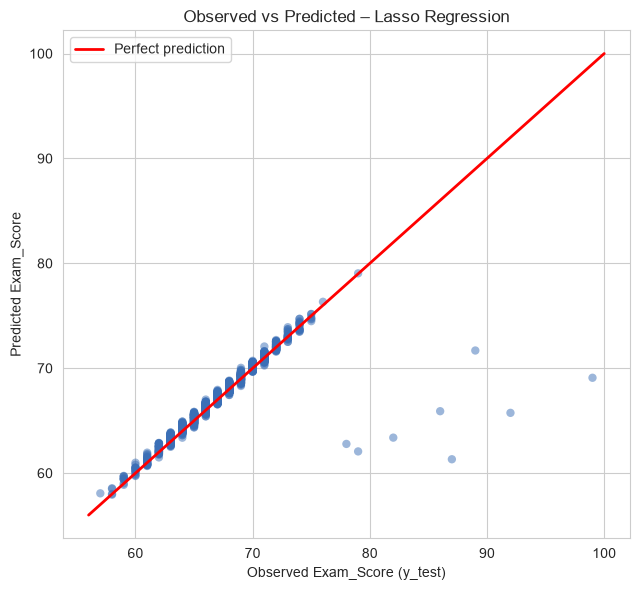

In [14]:
y_pred_best = preds[best_name]
plt.figure(figsize=(6.5,6))
plt.scatter(y_test, y_pred_best, alpha=0.5, color='#3b6fb6', edgecolor='none')
lims = [min(y_test.min(), y_pred_best.min())-1, max(y_test.max(), y_pred_best.max())+1]
plt.plot(lims, lims, color='red', linewidth=2, label='Perfect prediction')
plt.xlabel('Observed Exam_Score (y_test)'); plt.ylabel('Predicted Exam_Score')
plt.title(f'Observed vs Predicted – {best_name}'); plt.legend()
plt.tight_layout(); plt.savefig('figs/fig_obs_vs_pred.png', dpi=150); plt.show()

# PART 3 – CLASSIFICATION MODEL
## 3.1 Classifying the dataset based on the target variable

In [17]:
threshold = 70
df_clf = df_clean.copy()
df_clf['Score_Category'] = np.where(df_clf[target] >= threshold, 'High', 'Low')
print('Criterion: Exam_Score >= %d -> High, otherwise Low' % threshold)
print(df_clf['Score_Category'].value_counts())
print(df_clf['Score_Category'].value_counts(normalize=True).round(3))

Criterion: Exam_Score >= 70 -> High, otherwise Low
Score_Category
Low     4692
High    1442
Name: count, dtype: int64
Score_Category
Low     0.765
High    0.235
Name: proportion, dtype: float64


## 3.2 Building classification models

In [18]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, classification_report

Xc = df_clf.drop(columns=[target, 'Score_Category'])      # Exam_Score removed -> no data leakage
yc = df_clf['Score_Category']

clf_models = {
    'Logistic Regression'        : make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    'K-Nearest Neighbors'        : make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    'Support Vector Machine'     : make_pipeline(StandardScaler(), SVC(kernel='rbf', C=1.0)),
    'Decision Tree'              : DecisionTreeClassifier(max_depth=5, random_state=42),
    'Random Forest'              : RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
    'Naive Bayes (bonus)'        : GaussianNB(),
    'Gradient Boosting (bonus)'  : GradientBoostingClassifier(random_state=42),
}
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows, cv_preds = [], {}
for name, m in clf_models.items():
    pred = cross_val_predict(m, Xc, yc, cv=skf)
    cv_preds[name] = pred
    cm = confusion_matrix(yc, pred, labels=['Low','High'])      # [[TN FP],[FN TP]]
    rows.append({'Model': name, 'Confusion Matrix': str(cm.tolist()),
                 'Errors (FP + FN)': int(cm[0,1] + cm[1,0]),
                 'Accuracy': accuracy_score(yc, pred),
                 'Precision': precision_score(yc, pred, pos_label='High'),
                 'Recall'   : recall_score(yc, pred, pos_label='High'),
                 'F1-score' : f1_score(yc, pred, pos_label='High')})
clf_results = pd.DataFrame(rows)
print('Cross-Validation (5-fold) Classification Model Results')
display(clf_results.round(4))

Cross-Validation (5-fold) Classification Model Results


,Model,Confusion Matrix,Errors (FP + FN),Accuracy,Precision,Recall,F1-score
0,Logistic Regression,"[[4649, 43], [74, 1368]]",117,0.9809,0.9695,0.9487,0.9590
1,K-Nearest Neighbors,"[[4510, 182], [666, 776]]",848,0.8618,0.8100,0.5381,0.6467
2,Support Vector Machine,"[[4626, 66], [157, 1285]]",223,0.9636,0.9511,0.8911,0.9202
3,Decision Tree,"[[4345, 347], [508, 934]]",855,0.8606,0.7291,0.6477,0.6860
4,Random Forest,"[[4602, 90], [411, 1031]]",501,0.9183,0.9197,0.7150,0.8045
5,Naive Bayes (bonus),"[[4591, 101], [339, 1103]]",440,0.9283,0.9161,0.7649,0.8337
6,Gradient Boosting (bonus),"[[4584, 108], [289, 1153]]",397,0.9353,0.9144,0.7996,0.8531


In [19]:
best_clf_name = clf_results.sort_values(['F1-score','Accuracy'], ascending=False).iloc[0]['Model']
print('BEST-FIT CLASSIFIER:', best_clf_name)
print()
print(classification_report(yc, cv_preds[best_clf_name], digits=4))

BEST-FIT CLASSIFIER: Logistic Regression

              precision    recall  f1-score   support

        High     0.9695    0.9487    0.9590      1442
         Low     0.9843    0.9908    0.9876      4692

    accuracy                         0.9809      6134
   macro avg     0.9769    0.9698    0.9733      6134
weighted avg     0.9809    0.9809    0.9809      6134



## 3.3 No of elements on the target variable (best-fit classifier)

In [20]:
counts = pd.DataFrame({
    'Actual (dataset)'               : yc.value_counts(),
    f'Predicted by {best_clf_name}'  : pd.Series(cv_preds[best_clf_name]).value_counts(),
}).loc[['High','Low']]
counts.loc['Total'] = counts.sum()
display(counts)

,Actual (dataset),Predicted by Logistic Regression
High,1442,1411
Low,4692,4723
Total,6134,6134


# PART 4 – CLUSTER ANALYSIS
## 4.1 Building the Cluster Analysis (K-Means)

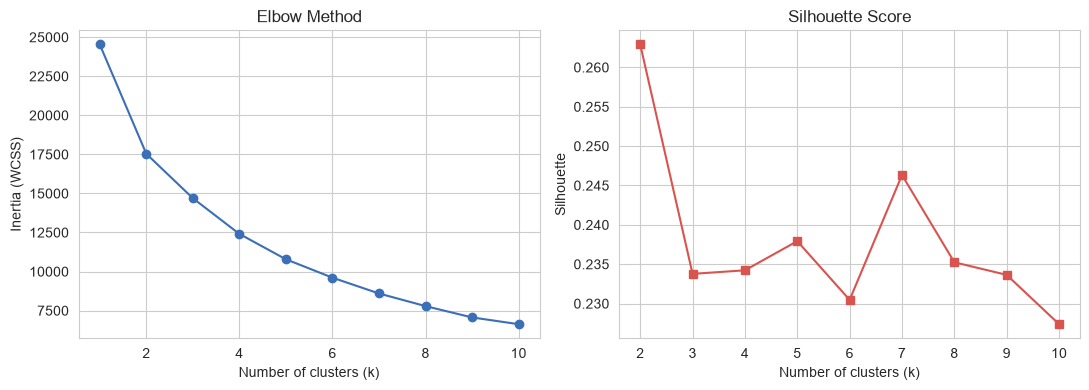

{2: 0.2629, 3: 0.2338, 4: 0.2342, 5: 0.2379, 6: 0.2305, 7: 0.2463, 8: 0.2352, 9: 0.2336, 10: 0.2274}


In [21]:
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

cluster_features = ['Hours_Studied','Attendance','Previous_Scores','Exam_Score']
Xcl = StandardScaler().fit_transform(df_clean[cluster_features])

inertia, sil = [], {}
for k in range(1, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xcl)
    inertia.append(km.inertia_)
    if k >= 2:
        sil[k] = silhouette_score(Xcl, km.labels_, sample_size=3000, random_state=42)

fig, ax = plt.subplots(1, 2, figsize=(11,4))
ax[0].plot(range(1,11), inertia, 'o-', color='#3b6fb6'); ax[0].set_title('Elbow Method')
ax[0].set_xlabel('Number of clusters (k)'); ax[0].set_ylabel('Inertia (WCSS)')
ax[1].plot(list(sil.keys()), list(sil.values()), 's-', color='#d9534f'); ax[1].set_title('Silhouette Score')
ax[1].set_xlabel('Number of clusters (k)'); ax[1].set_ylabel('Silhouette')
plt.tight_layout(); plt.savefig('figs/fig_elbow_silhouette.png', dpi=150); plt.show()
print({k: round(v, 4) for k, v in sil.items()})

Silhouette for k = 4 : 0.2342 | best silhouette overall: k = 2 (0.2629)
Chosen number of clusters (k) = 4


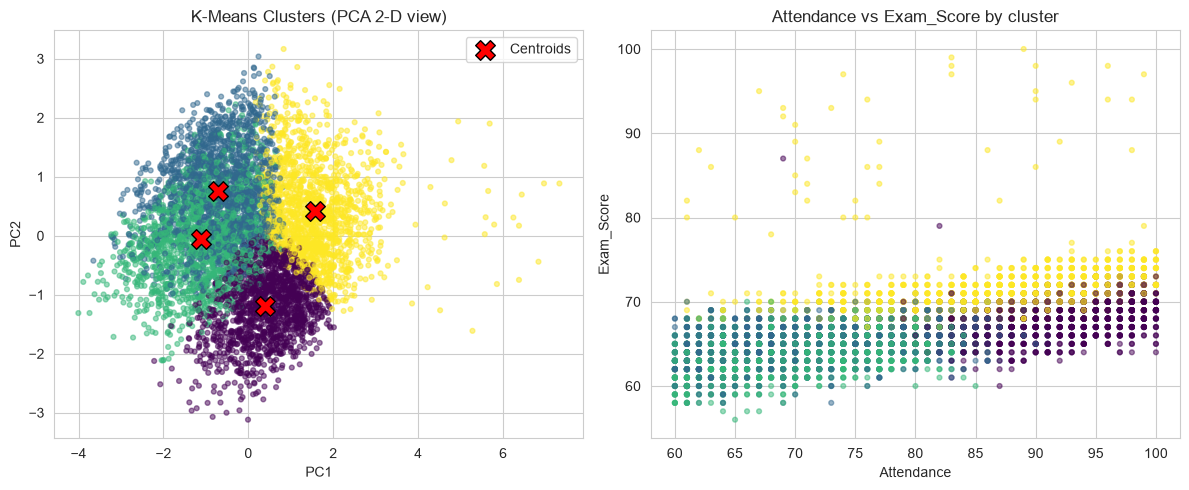

PCA explained variance: [0.437 0.259]


In [22]:
# Optimal k: the elbow curve bends and starts to flatten around k = 4, and silhouette scores are
# almost identical for k = 3 to 6 (about 0.23), so k = 4 gives balanced, interpretable groups.
optimal_k = 4
print('Silhouette for k = 4 :', round(sil[4], 4), '| best silhouette overall: k =', max(sil, key=sil.get), '(%.4f)' % max(sil.values()))
print('Chosen number of clusters (k) =', optimal_k)

km = KMeans(n_clusters=optimal_k, n_init=10, random_state=42).fit(Xcl)
df_cl = df_clean.copy()
df_cl['Cluster'] = km.labels_

pca = PCA(n_components=2, random_state=42)
pc = pca.fit_transform(Xcl)
centers_pc = pca.transform(km.cluster_centers_)
fig, ax = plt.subplots(1, 2, figsize=(12,5))
sc = ax[0].scatter(pc[:,0], pc[:,1], c=km.labels_, cmap='viridis', alpha=0.5, s=12)
ax[0].scatter(centers_pc[:,0], centers_pc[:,1], c='red', marker='X', s=200, edgecolor='black', label='Centroids')
ax[0].set_title('K-Means Clusters (PCA 2-D view)'); ax[0].set_xlabel('PC1'); ax[0].set_ylabel('PC2'); ax[0].legend()
ax[1].scatter(df_cl['Attendance'], df_cl['Exam_Score'], c=km.labels_, cmap='viridis', alpha=0.5, s=12)
ax[1].set_title('Attendance vs Exam_Score by cluster'); ax[1].set_xlabel('Attendance'); ax[1].set_ylabel('Exam_Score')
plt.tight_layout(); plt.savefig('figs/fig_kmeans_clusters.png', dpi=150); plt.show()
print('PCA explained variance:', pca.explained_variance_ratio_.round(3))

## 4.2 Strategy Formulation

In [23]:
profile = df_cl.groupby('Cluster').agg(
    Students=('Exam_Score','size'),
    Hours_Studied=('Hours_Studied','mean'), Attendance=('Attendance','mean'),
    Previous_Scores=('Previous_Scores','mean'), Exam_Score=('Exam_Score','mean'),
    Tutoring_Sessions=('Tutoring_Sessions','mean'), Sleep_Hours=('Sleep_Hours','mean'),
    Motivation_Level=('Motivation_Level','mean'), Parental_Involvement=('Parental_Involvement','mean'),
    Access_to_Resources=('Access_to_Resources','mean'))
profile['Share_%'] = (profile['Students'] / profile['Students'].sum() * 100)
display(profile.round(2))

,Students,Hours_Studied,Attendance,Previous_Scores,Exam_Score,Tutoring_Sessions,Sleep_Hours,Motivation_Level,Parental_Involvement,Access_to_Resources,Share_%
Cluster,,,,,,,,,,,
0,1462,16.82,91.50,67.65,68.00,1.32,7.01,0.91,1.09,1.06,23.83
1,1607,17.90,72.17,88.16,65.31,1.23,7.03,0.92,1.07,1.10,26.20
2,1589,20.06,70.48,62.48,64.27,1.27,7.07,0.87,1.05,1.06,25.90
3,1476,25.38,87.12,81.79,71.33,1.35,7.03,0.92,1.14,1.18,24.06


## Final summary of key results

In [24]:
print('Rows after cleaning/outlier removal :', len(df_clean))
print('Best regression model               :', best_name, '| R² =', round(results_sorted.loc[0,'R² (test)'], 4), '| MSE =', round(results_sorted.loc[0,'MSE'], 4))
print('Best classifier                     :', best_clf_name)
print('Optimal clusters                    :', optimal_k)

Rows after cleaning/outlier removal : 6134
Best regression model               : Lasso Regression | R² = 0.7614 | MSE = 3.2513
Best classifier                     : Logistic Regression
Optimal clusters                    : 4
